# 🚀 Fine-Tuning VGG-16 Object Detector su Google Colab con Ultralytics HUB

Questo notebook guida gli studenti nell'esecuzione del **training e fine-tuning** del modello **VGG-16 Object Detector** direttamente dall'ambiente cloud di **Google Colab**, sfruttando le risorse hardware gratuite (TPU / GPU) e sincronizzando metriche ed epoche in tempo reale sulla dashboard di **Ultralytics HUB**.

---
### 📋 Riepilogo dei passaggi operativi:
1. **Passo 1:** Configurare l'acceleratore hardware (TPU o GPU) in Google Colab.
2. **Passo 2:** Impostare `freeze: 1` nelle *Advanced Settings* su Ultralytics HUB per preservare i pesi del backbone VGG-16 pre-addestrato.
3. **Passo 3:** Selezionare la scheda *Local Training* sulla piattaforma Ultralytics e copiare il comando generato.
4. **Cella 1:** Installare i requisiti (`ultralytics>=8.4.214`) e verificare l'ambiente.
5. **Cella 2:** Avviare il training da riga di comando bash con streaming su HUB.

## ⚙️ Passo 1: Selezionare l'Acceleratore Hardware (TPU / GPU)

Per addestrare la rete in modo rapido, è fondamentale attivare un acceleratore hardware in Google Colab:
1. Nel menu in alto di Colab, clicca su **Runtime** $\rightarrow$ **Change runtime type** (Modifica tipo di runtime).
2. Sotto la voce **Hardware accelerator**, seleziona **`v5e-1 TPU`** (oppure **`T4 GPU`**).
3. Clicca sul pulsante blu **Save** (Salva).

<div align="center">
  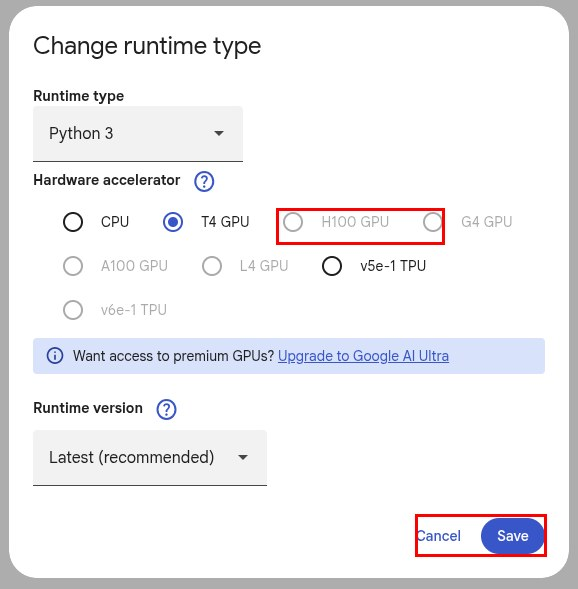
  <p><i>Figura 1: Selezione della TPU v5e-1 (o GPU T4) e salvataggio del tipo di runtime in Google Colab.</i></p>
</div>

## 🔒 Passo 2: Congelare il Backbone Pre-addestrato (`freeze: 1`)

Sulla piattaforma Ultralytics HUB, prima di avviare l'addestramento sul custom dataset target:
1. Nella schermata di configurazione del training del modello, espandi la sezione **Advanced Settings**.
2. Individua il parametro **`freeze`** e impostalo su **`1`** (`freeze: 1`).

> **💡 Perché freeze = 1?**  
> Il nostro detector è composto da un **backbone VGG-16 pre-addestrato** (indice `0`) e da un **neck/head di detection** (FPN + PAN + Detect Head multi-scala).  
> Impostando `freeze: 1`, i pesi della VGG-16 pre-addestrata rimangono **congelati** (non vengono aggiornati dal gradiente). In questo modo la rete conserva intatte le feature visive apprese e concentra l'addestramento esclusivamente sull'adattamento dell'head di localizzazione (bounding box) e classificazione al nuovo dataset target, prevenendo il *catastrophic forgetting*.

<div align="center">
  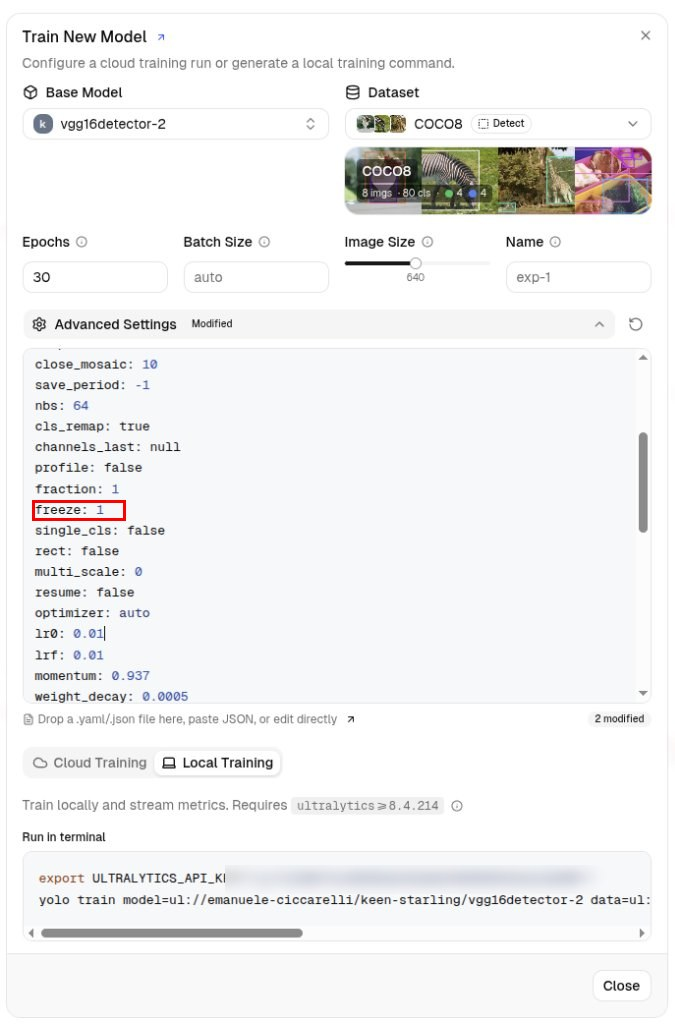
  <p><i>Figura 2: Impostazione del parametro freeze: 1 nelle Advanced Settings di Ultralytics HUB.</i></p>
</div>

## 💻 Passo 3: Copiare il Comando da "Local Training" su Ultralytics HUB

Sulla piattaforma Ultralytics HUB, nella schermata di avvio del training:
1. Clicca sulla scheda **Local Training** (Addestramento locale).
2. Individua il riquadro **Run in terminal** contenente il comando generato per il tuo modello con la tua `ULTRALYTICS_API_KEY`.
3. **Copia l'intero comando visualizzato nel riquadro**: dovrai incollarlo nella **Cella 2** di questo notebook (più in basso) per avviare il training locale su Google Colab con streaming live sulla tua dashboard HUB.

<div align="center">
  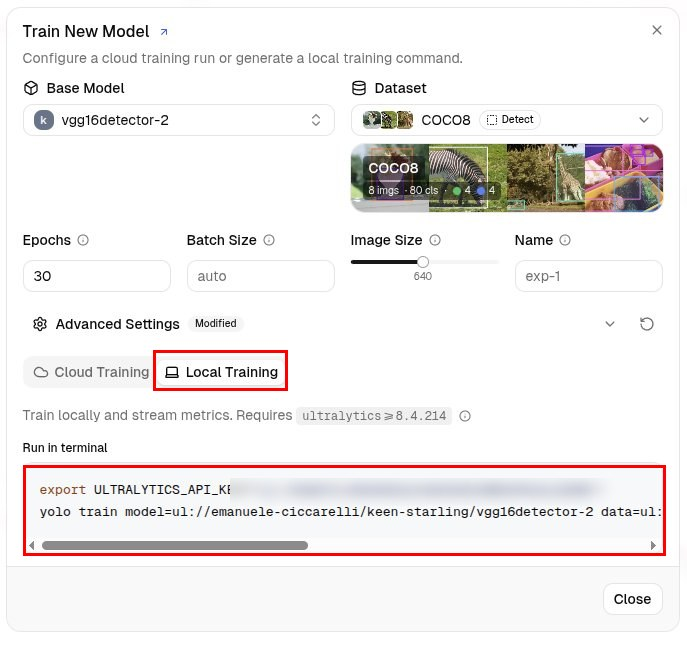
  <p><i>Figura 3: Scheda Local Training con comando terminale pre-configurato.</i></p>
</div>

## 📦 Cella 1: Installazione dei Requisiti
Esegui la cella seguente per installare Ultralytics e verificare l'ambiente di esecuzione.

In [ ]:
# 1. Installazione del pacchetto Ultralytics (versione richiesta >= 8.4.214)
!pip install -q "ultralytics>=8.4.214"

# 2. Verifica dell'ambiente e dell'acceleratore hardware disponibile
import ultralytics
ultralytics.checks()

## 🚀 Cella 2: Avvio del Training Locale con Streaming HUB

Incolla nella cella di codice sottostante il comando che hai copiato al **Passo 3** dalla scheda **Local Training** di Ultralytics HUB.

> ⚠️ **ATTENZIONE PER GLI STUDENTI:**  
> - Non eseguire la cella senza aver prima incollato il tuo comando personalizzato!  
> - Il comando copiato dalla piattaforma contiene già la tua `ULTRALYTICS_API_KEY`, l'URL del tuo modello e il nome del tuo progetto.  
> - Assicurati che nel comando rimanga il parametro `freeze=1` per non sovrascrivere il backbone VGG-16 pre-addestrato.

In [ ]:
%%bash
# =============================================================================
# ⬇️ INCOLLA QUI SOTTO IL TUO COMANDO COPIATO DA ULTRALYTICS HUB (PASSO 3) ⬇️
# =============================================================================
# (Sostituisci questo blocco di esempio incollando direttamente il tuo comando preso da "Run in terminal")

export ULTRALYTICS_API_KEY="INSERISCI_QUI_LA_TUA_API_KEY"

yolo train \
  model=ul://TUO_USERNAME/TUO_PROGETTO/vgg16detector-2 \
  data=ul://ultralytics/datasets/coco8 \
  task=detect \
  project=TUO_USERNAME/TUO_PROGETTO \
  epochs=30 \
  freeze=1
